# Buổi C8: Dữ liệu lệch nhóm, khi "đúng 95%" chẳng có nghĩa gì

**Hiện trường.** Chị Hạnh quay lại với việc sàng lọc, nhưng lần này là **tình huống thật hơn**: trong 100 người đến khám, chỉ khoảng **5 người** có khối u ác tính. Mô hình đầu tiên báo "độ đúng 95%" và cả phòng vỗ tay. Chị Hạnh hỏi nhỏ: *"Nếu em in ra dòng chữ 'lành tính' cho mọi người thì có đúng 95% không?"*

Có. Đó là **cái bẫy độ đúng** đã gặp ở C2, nhưng bây giờ nó là **tình huống chuẩn** chứ không phải ngoại lệ: phát hiện gian lận, bệnh hiếm, hỏng máy, khách rời bỏ... gần như bài toán phân loại nào ngoài đời cũng lệch nhóm.

**Câu hỏi của buổi này:** *khi một nhóm hiếm, đo thế nào cho thật, và có những cách nào giúp mô hình "để ý" đến nhóm hiếm?*

**Lưu ý quan trọng:** bộ ung thư vú gốc có 37% ác tính. Để minh họa, ta **cố ý giữ lại chỉ 20 ca ác tính** (khoảng 5%) và chỉ dùng **6 cột khó** (ranh giới nhập nhằng): đây là **dữ liệu lệch do ta tạo**, không phải tỉ lệ thật. Chỉ để học, không dùng chẩn đoán. Buổi này dùng lại cú pháp từ A1 đến C7; chỉ giải thích điều **mới**.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 1 | Dựng dữ liệu lệch và nhìn thấy cái bẫy độ đúng |
| Chặng 2 | Đo cho thật: recall, precision và đường PR (đường ROC dễ tự mãn) |
| Chặng 3 | Cách 1: `class_weight`, phạt nặng khi bỏ sót nhóm hiếm |
| Chặng 4 | Cách 2: dời ngưỡng quyết định |
| Chặng 5 | Cách 3: nhân bản nhóm hiếm, và cái bẫy rò rỉ dữ liệu |
| Chặng 6 | Chỉ có 20 ca hiếm: kết quả bấp bênh đến đâu, và phán quyết |

## Chặng 1: Dựng dữ liệu lệch và nhìn thấy cái bẫy độ đúng

**Câu hỏi:** một mô hình "ngu" (luôn đoán lành tính) đạt bao nhiêu, và mô hình logistic thật thì hơn bao nhiêu?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

In [2]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, confusion_matrix
bc = load_breast_cancer(as_frame=True)
hard_cols = ["mean smoothness", "mean symmetry", "mean fractal dimension", "mean texture", "texture error", "smoothness error"]
rng = np.random.RandomState(1)
malignant_idx = np.where(bc.target == 0)[0]
benign_idx = np.where(bc.target == 1)[0]
keep = np.concatenate([benign_idx, rng.choice(malignant_idx, 20, replace=False)])
X = bc.data.iloc[keep][hard_cols].reset_index(drop=True)
y = (1 - bc.target.iloc[keep]).reset_index(drop=True)
print("rows:", len(y), "| malignant:", int(y.sum()), f"({y.mean():.1%})")
cv5 = StratifiedKFold(5, shuffle=True, random_state=0)
def oof_scores(model, X=X, y=y):
    return cross_val_predict(model, X, y, cv=cv5, method="predict_proba")[:, 1]
dummy_pred = cross_val_predict(DummyClassifier(strategy="most_frequent"), X, y, cv=cv5)
base = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
s_base = oof_scores(base)
p_base = (s_base >= 0.5).astype(int)
for name, p in [("always 'benign'", dummy_pred), ("logistic, threshold 0.5", p_base)]:
    print(f"{name:<26} accuracy {accuracy_score(y, p):.3f} | recall {recall_score(y, p):.3f} | precision {precision_score(y, p, zero_division=0):.3f}")
print("confusion matrix (rows true, cols predicted):\n", confusion_matrix(y, p_base))

rows: 377 | malignant: 20 (5.3%)
always 'benign'            accuracy 0.947 | recall 0.000 | precision 0.000
logistic, threshold 0.5    accuracy 0.952 | recall 0.200 | precision 0.667
confusion matrix (rows true, cols predicted):
 [[355   2]
 [ 16   4]]


**Giải thích từng dòng**

- `np.where(bc.target == 0)[0]`: trong dữ liệu gốc `target == 0` là **ác tính** (ta đã lật nhãn ở các bài trước; ở đây giữ nhãn gốc để lấy chỉ số rồi lật sau).
- `rng.choice(malignant_idx, 20, replace=False)`: bốc **ngẫu nhiên 20** ca ác tính, không lặp. Giữ **toàn bộ** ca lành tính (357).
- `hard_cols = [...]`: sáu cột *khó*, ranh giới nhập nhằng, để bài toán không dễ như C2 (nếu dùng cả 30 cột thì mô hình gần đạt 100%, mất ý nghĩa bài học).
- `y = (1 - bc.target.iloc[keep]).reset_index(drop=True)`: đổi nhãn: 1 là **ác tính** (nhóm hiếm ta cần bắt).
- `DummyClassifier(strategy="most_frequent")`: (đã học ở C2) mô hình ngu luôn đoán nhóm đông.
- `def oof_scores(model, X=X, y=y):`: **hàm tự viết** trả về điểm xác suất **ngoài-tập-học** (out-of-fold) của mọi dòng, bằng `cross_val_predict` (đã học ở C2). Mỗi dòng được chấm bởi mô hình *chưa từng thấy nó*. Ta dùng lại hàm này cả bài.
- `p_base = (s_base >= 0.5).astype(int)`: đổi xác suất thành nhãn bằng ngưỡng 0,5.

**Cách đọc**

- **Con số:** dữ liệu có **377** dòng, trong đó **20** ác tính (5%). Mô hình "luôn đoán lành tính" đạt độ đúng **0,947** với recall bằng 0. Logistic thật đạt độ đúng **0,952**, chỉ nhỉnh hơn mô hình ngu **0,5 điểm phần trăm**, nhưng recall chỉ **0,20**: trong 20 ca ác tính, mô hình **bỏ sót 16**.
- **Bức tranh (ma trận nhầm lẫn):** ô "lành tính đoán đúng" chiếm gần hết bảng, che khuất hàng ác tính nhỏ xíu.
- **Ý nghĩa:** khoảng cách giữa mô hình ngu và mô hình thật **nhỏ trên độ đúng** nhưng **lớn trên recall**. Khi lệch nhóm, *đừng bao giờ báo cáo độ đúng một mình*.

**Mang về chặng 1:** độ đúng của mô hình ngu = tỉ lệ nhóm đông; mọi mô hình phải được so với **mốc ngu** đó, và đo bằng recall của nhóm hiếm.

## Chặng 2: Đo cho thật, recall, precision và đường PR

**Câu hỏi:** AUC (C2) có cứu ta không?

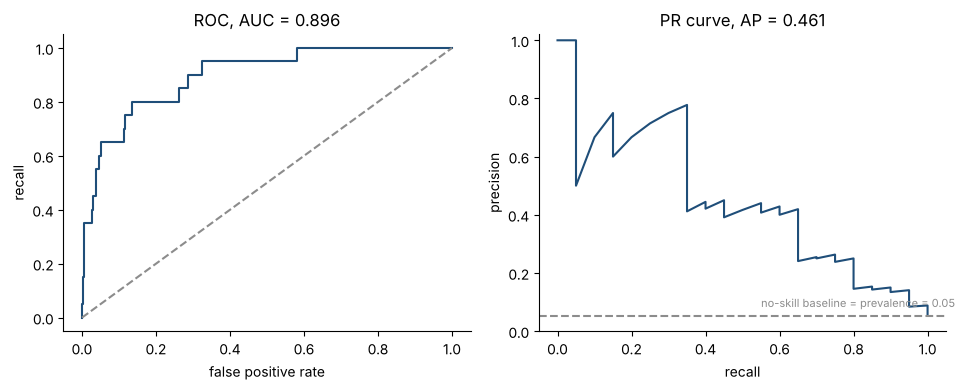

In [3]:
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score
fpr, tpr, _ = roc_curve(y, s_base)
prec, rec, _ = precision_recall_curve(y, s_base)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(fpr, tpr, color=BLUE); axes[0].plot([0, 1], [0, 1], "--", color=GRAY)
axes[0].set(xlabel="false positive rate", ylabel="recall", title=f"ROC, AUC = {roc_auc_score(y, s_base):.3f}")
axes[1].plot(rec, prec, color=BLUE); axes[1].axhline(y.mean(), ls="--", color=GRAY)
axes[1].set(xlabel="recall", ylabel="precision", ylim=(0, 1.02), title=f"PR curve, AP = {average_precision_score(y, s_base):.3f}")
axes[1].text(0.55, y.mean() + 0.03, f"no-skill baseline = prevalence = {y.mean():.2f}", fontsize=8, color=GRAY)
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `precision_recall_curve(y, s_base)`: (đã học ở C2) đường precision đối recall khi quét ngưỡng.
- `average_precision_score(y, s_base)`: **AP** (average precision): diện tích dưới đường PR, một con số tóm tắt đường PR.
- `axes[1].axhline(y.mean(), ls="--", color=GRAY)`: đường **mốc không biết gì** của PR là một đường ngang tại **tỉ lệ nhóm hiếm** (ở ROC thì mốc là đường chéo).

**Cách đọc**

- **Con số:** AUC **0,896** (nghe khá đẹp), nhưng AP chỉ **0,461** trong khi mốc không biết gì của AP là **0,053**.
- **Bức tranh:** đường ROC cong lên khá xa đường chéo, trông tử tế. Đường PR thì tụt dần: muốn bắt thêm ca ác tính (recall tăng) thì precision rơi mạnh, vì mỗi ca báo nhầm lành tính thành ác tính là **một trong 357 ca lành tính** nhưng chỉ có 20 ca đúng để pha loãng.
- **Ý nghĩa:** ROC dùng *tỉ lệ* báo nhầm trên **357 ca lành tính** nên 10 ca báo nhầm vẫn chỉ là 3% (nhỏ), còn precision tính trên **số ca bị báo**, nên 10 ca báo nhầm kèm 10 ca đúng cho 50%. **Khi nhóm hiếm, PR trung thực hơn ROC.** Hãy báo cáo cả hai, nhưng ra quyết định bằng PR.

**Mang về chặng 2:** khi lệch nhóm, dùng recall, precision, đường PR và AP; so AP với **tỉ lệ nhóm hiếm** (mốc không biết gì).

## Chặng 3: Cách 1, `class_weight`, phạt nặng khi bỏ sót nhóm hiếm

**Câu hỏi:** có cách nào *bảo* mô hình coi trọng nhóm hiếm ngay lúc học?

`class_weight="balanced"` nhân điểm phạt của mỗi dòng với **trọng số tỉ lệ nghịch với số ca của nhóm**: một ca ác tính bị bỏ sót bị phạt nặng gấp (357 / 20) ≈ 18 lần một ca lành tính bị báo nhầm. Máy sẽ *ngại* bỏ sót hơn.

In [4]:
weighted = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000))
s_w = oof_scores(weighted)
p_w = (s_w >= 0.5).astype(int)
print("cases per class: benign", int((y == 0).sum()), "| malignant", int((y == 1).sum()))
print("weight ratio ≈", round((y == 0).sum() / (y == 1).sum(), 1), "to 1")
for name, p, s in [("default", p_base, s_base), ("class_weight=balanced", p_w, s_w)]:
    print(f"{name:<22} accuracy {accuracy_score(y, p):.3f} | recall {recall_score(y, p):.3f} | precision {precision_score(y, p):.3f} | AUC {roc_auc_score(y, s):.3f} | AP {average_precision_score(y, s):.3f} | missed {int(((y == 1) & (p == 0)).sum())} | false alarms {int(((y == 0) & (p == 1)).sum())}")

cases per class: benign 357 | malignant 20
weight ratio ≈ 17.8 to 1
default                accuracy 0.952 | recall 0.200 | precision 0.667 | AUC 0.896 | AP 0.461 | missed 16 | false alarms 2
class_weight=balanced  accuracy 0.828 | recall 0.800 | precision 0.208 | AUC 0.878 | AP 0.392 | missed 4 | false alarms 61


**Giải thích từng dòng**

- `LogisticRegression(class_weight="balanced", ...)`: **mới:** `class_weight="balanced"` tự tính trọng số theo tần suất nhóm. Cũng có ở `SVC`, `DecisionTreeClassifier`, `RandomForest`... nhưng **không** có ở k-NN.
- `print("cases per class: ...")`: đếm số ca mỗi nhóm để tính tỉ lệ trọng số.
- `((y == 1) & (p == 0)).sum()`: (đã học) đếm ca **bỏ sót**: thật là ác tính (1) mà máy đoán lành tính (0); `&` là "và" cho mảng. Tương tự với **báo nhầm**.

**Cách đọc**

- **Con số:** recall tăng từ **0,20** lên **0,80** (bỏ sót giảm từ 16 xuống 4 ca), nhưng precision giảm từ 0,67 xuống **0,21** và độ đúng giảm từ 0,952 xuống 0,828; báo nhầm tăng từ 2 lên **61**. AUC (0,90 so với 0,88) và AP (0,46 so với 0,39) **không tăng, thậm chí giảm nhẹ**.
- **Ý nghĩa:** `class_weight` *không làm mô hình giỏi hơn*; nó **dịch điểm cân bằng** giữa bỏ sót và báo nhầm (cùng đường PR, đổi điểm đứng). Đây là một **quyết định kinh doanh** (bỏ sót đắt hơn báo nhầm bao nhiêu?) chứ không phải mẹo kỹ thuật. Vì AUC, AP không tăng, độ đúng thấp đi là *cái giá hiển nhiên* của việc bắt thêm ca hiếm.

**Mang về chặng 3:** `class_weight="balanced"` đổi điểm đứng trên đường PR (tăng recall, giảm precision), không nâng chất lượng xếp hạng.

## Chặng 4: Cách 2, dời ngưỡng quyết định

**Câu hỏi:** nếu `class_weight` chỉ là dịch điểm đứng, sao không dịch thẳng ngưỡng cho khỏi phải học lại?

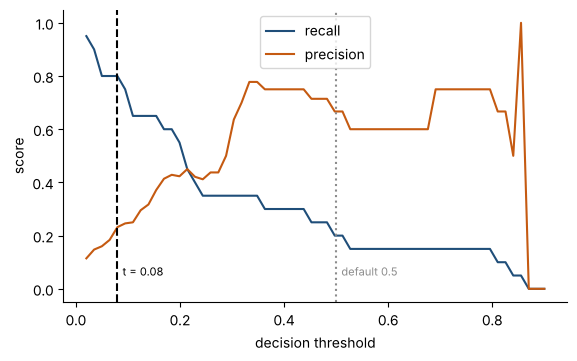

threshold 0.08: recall 0.800 | precision 0.232 | accuracy 0.849 | missed 4 | false alarms 53


In [5]:
thresholds = np.linspace(0.02, 0.9, 60)
rec_t = [recall_score(y, (s_base >= t).astype(int)) for t in thresholds]
prec_t = [precision_score(y, (s_base >= t).astype(int), zero_division=0) for t in thresholds]
target_recall = 0.8
t_star = max(t for t, r in zip(thresholds, rec_t) if r >= target_recall)
p_t = (s_base >= t_star).astype(int)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(thresholds, rec_t, color=BLUE, label="recall"); ax.plot(thresholds, prec_t, color="#C55A11", label="precision")
ax.axvline(0.5, color=GRAY, ls=":"); ax.axvline(t_star, color="black", ls="--")
ax.text(t_star + 0.01, 0.05, f"t = {t_star:.2f}", fontsize=8); ax.text(0.51, 0.05, "default 0.5", fontsize=8, color=GRAY)
ax.set(xlabel="decision threshold", ylabel="score"); ax.legend(); plt.show()
print(f"threshold {t_star:.2f}: recall {recall_score(y, p_t):.3f} | precision {precision_score(y, p_t):.3f} | accuracy {accuracy_score(y, p_t):.3f} | missed {int(((y == 1) & (p_t == 0)).sum())} | false alarms {int(((y == 0) & (p_t == 1)).sum())}")

**Giải thích từng dòng**

- `thresholds = np.linspace(0.02, 0.9, 60)`: 60 ngưỡng từ 0,02 đến 0,9.
- `t_star = max(t for t, r in zip(thresholds, rec_t) if r >= target_recall)`: **ngưỡng cao nhất vẫn giữ recall ≥ 0,8**: tức là *nghiêm nhất có thể* mà vẫn bắt đủ 80% ca ác tính (ngưỡng cao hơn thì ít báo nhầm hơn). `max(... for ... if ...)` là biểu thức sinh lọc điều kiện.
- `color="#C55A11"`: một màu cam trầm cho đường precision (`BLUE` và `GRAY` đã có sẵn từ `setup_cell`).

**Cách đọc**

- **Con số:** để bắt ≥ 80% ca ác tính, ngưỡng phải hạ từ 0,5 xuống **0,08**; kết quả recall **0,80**, precision **0,23**, báo nhầm **53** ca.
- **Bức tranh:** recall (xanh) đi xuống và precision (cam) đi lên khi ngưỡng tăng: một cái *bập bênh*. Ngưỡng mặc định 0,5 nằm ở chỗ recall đã thấp.
- **Ý nghĩa:** dời ngưỡng cho **cùng loại kết quả** như `class_weight` mà *chọn được chính xác điểm đứng theo yêu cầu* ("phải bắt ≥ 80%"), không phải huấn luyện lại. Trong thực hành nên **chọn ngưỡng bằng dữ liệu ngoài-tập-học như ta đã làm (`cross_val_predict`)**, đừng chọn trên chính tập học.

**Mang về chặng 4:** dời ngưỡng là cách đơn giản nhất để đặt điểm đứng theo yêu cầu nghiệp vụ; chọn ngưỡng trên điểm out-of-fold.

## Chặng 5: Cách 3, nhân bản nhóm hiếm, và cái bẫy rò rỉ dữ liệu

**Câu hỏi:** nhiều người chữa lệch bằng cách **nhân bản ca hiếm** (oversampling) cho cân. Có gì cần cẩn thận?

Có một cái bẫy rất phổ biến: nhân bản **trước khi** chia kiểm định chéo. Khi đó một ca ác tính xuất hiện cả ở phần học lẫn phần thi (bản sao), mô hình "nhận ra" ca đã gặp và điểm số **phình lên giả tạo**. Ta đo cả hai cách:

In [6]:
from sklearn.utils import resample
def oversample(Xa, ya, seed=0):
    minority = ya == 1
    Xm = resample(Xa[minority], n_samples=int((~minority).sum()), replace=True, random_state=seed)
    Xo = pd.concat([Xa[~minority], Xm]); yo = np.r_[np.zeros((~minority).sum()), np.ones(len(Xm))]
    return Xo, yo
# RIGHT: oversample only the training part of each fold
oof_right = np.zeros(len(y))
for tr, te in cv5.split(X, y):
    Xo, yo = oversample(X.iloc[tr], y.iloc[tr].values)
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(Xo, yo)
    oof_right[te] = m.predict_proba(X.iloc[te])[:, 1]
# WRONG: oversample first, then cross-validate
Xw, yw = oversample(X, y.values)
Xw = Xw.reset_index(drop=True); yw = pd.Series(yw)
s_wrong = cross_val_predict(base, Xw, yw, cv=cv5, method="predict_proba")[:, 1]
p_right = (oof_right >= 0.5).astype(int); p_wrong = (s_wrong >= 0.5).astype(int)
print(f"right  (oversample inside folds): recall {recall_score(y, p_right):.3f} | precision {precision_score(y, p_right):.3f} | AP {average_precision_score(y, oof_right):.3f}")
print(f"wrong  (oversample before CV)   : recall {recall_score(yw, p_wrong):.3f} | precision {precision_score(yw, p_wrong):.3f} | AP {average_precision_score(yw, s_wrong):.3f}  <- looks better, but is leaked")

right  (oversample inside folds): recall 0.800 | precision 0.208 | AP 0.389
wrong  (oversample before CV)   : recall 0.880 | precision 0.846 | AP 0.917  <- looks better, but is leaked


**Giải thích từng dòng**

- `from sklearn.utils import resample`: **mới:** `resample` bốc mẫu **có hoàn lại** (`replace=True`) từ một bảng.
- `def oversample(Xa, ya, seed=0):`: hàm tự viết: bốc lại ca hiếm cho đủ **bằng số ca đông**, rồi ghép với ca đông.
- `for tr, te in cv5.split(X, y):`: tự chạy từng phần của kiểm định chéo để **chỉ nhân bản trên phần học** của mỗi vòng; `tr`, `te` là vị trí dòng học và thi.
- `Xo, yo = oversample(X.iloc[tr], y.iloc[tr].values)`: nhân bản **chỉ phần học**; phần thi `te` giữ nguyên, không có bản sao.
- `Xw, yw = oversample(X, y.values)`: **SAI:** nhân bản **toàn bộ** rồi mới chia: bản sao của cùng một ca rơi vào cả hai phía.
- `recall_score(yw, p_wrong)`: đo trên nhãn đã nhân bản `yw` (đó chính là chỗ gian lận: đo trên cả các bản sao).

**Cách đọc**

- **Con số:** cách **đúng** cho recall 0,80, precision 0,21, AP 0,39. Cách **sai** cho recall 0,88, precision 0,85, AP 0,92: **đẹp hơn hẳn nhưng là giả**, vì mô hình đã thấy bản sao của ca thi lúc học.
- **Ý nghĩa:** quy tắc nghề đã gặp từ A4 và B4 áp dụng lại: **mọi bước biến đổi dữ liệu có nhìn vào nhãn hoặc nhân bản dòng phải nằm *bên trong* vòng kiểm định chéo**, không đứng trước nó. Thư viện `imbalanced-learn` làm việc này gọn hơn bằng pipeline riêng; ý tưởng giống hệt.
- **Cách đúng cũng chỉ cho điểm đứng, không phải phép màu:** recall/precision của oversampling đúng cách tương đương `class_weight` và dời ngưỡng: ba cách là **ba lối đi đến cùng một chỗ**. Nhân bản dòng thêm hiểm họa: mô hình dễ *thuộc lòng* 20 ca bị lặp lại.

**Mang về chặng 5:** nhân bản nhóm hiếm chỉ trên **phần học của mỗi vòng**; nhân bản trước khi chia gây rò rỉ và điểm giả.

## Chặng 6: Chỉ có 20 ca hiếm, kết quả bấp bênh đến đâu, và phán quyết

**Câu hỏi:** recall 0,8 trên **20 ca** đáng tin đến mức nào?

In [7]:
rng_b = np.random.RandomState(0)
pos_idx = np.where(y.values == 1)[0]
hit = (p_t[pos_idx] == 1).astype(int)
boot = [rng_b.choice(hit, len(hit), replace=True).mean() for _ in range(5000)]
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"recall at threshold {t_star:.2f}: {hit.mean():.2f} on {len(hit)} malignant cases | 95% bootstrap interval: {lo:.2f} to {hi:.2f}")
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=20, random_state=0)
rec_runs = []
for tr, te in rcv.split(X, y):
    m = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000)).fit(X.iloc[tr], y.iloc[tr])
    rec_runs.append(recall_score(y.iloc[te], m.predict(X.iloc[te])))
print(f"recall per fold over 100 folds: mean {np.mean(rec_runs):.2f}, std {np.std(rec_runs):.2f}, min {np.min(rec_runs):.2f}, max {np.max(rec_runs):.2f}")

recall at threshold 0.08: 0.80 on 20 malignant cases | 95% bootstrap interval: 0.60 to 0.95


recall per fold over 100 folds: mean 0.82, std 0.21, min 0.00, max 1.00


**Giải thích từng dòng**

- `hit = (p_t[pos_idx] == 1).astype(int)`: với mỗi ca ác tính thật: 1 nếu máy bắt được, 0 nếu bỏ sót.
- `rng_b.choice(hit, len(hit), replace=True).mean()`: (đã học ở C2) **bootstrap**: bốc lại 20 ca có hoàn lại 5000 lần, tính recall mỗi lần.
- `np.percentile(boot, [2.5, 97.5])`: khoảng chứa 95% các giá trị bootstrap.
- `rec_runs.append(recall_score(...))`: recall của **từng phần thi** (mỗi phần chỉ có khoảng 4 ca ác tính!).

**Cách đọc**

- **Con số:** recall 0,80 trên 20 ca có **khoảng tin cậy 95% từ 0,60 đến 0,95**. Qua 100 phần thi, recall mỗi phần dao động từ 0,00 đến 1,00 (độ lệch chuẩn 0,21), vì mỗi phần chỉ chứa khoảng 4 ca ác tính: **bỏ sót thêm một ca là recall rơi 25 điểm**.
- **Ý nghĩa:** với nhóm hiếm, **độ không chắc chắn lớn hơn ta tưởng**. Con số "recall 0,8" thực ra là "có lẽ trong khoảng nửa đến gần hết". Muốn con số chắc hơn thì cần **thêm ca hiếm** (không phải thêm ca đông).

## Phán quyết và bài học nghề

**Phán quyết cho chị Hạnh.** Dùng logistic có chuẩn hóa, **dời ngưỡng** theo yêu cầu "bắt ≥ 80% ca ác tính" (chọn trên điểm out-of-fold), báo cáo **recall, precision, AP kèm khoảng tin cậy**, không báo độ đúng. Nói rõ với bệnh viện: *cứ 100 người được báo, chỉ một phần nhỏ thực sự có u ác tính; phần còn lại là báo nhầm cần xét nghiệm thêm*. Đó là cái giá của việc không bỏ sót.

**Bài học nghề.**

1. **Mốc ngu = tỉ lệ nhóm đông.** Mọi độ đúng phải so với nó.
2. **Đo bằng recall, precision, PR/AP**; ROC/AUC dễ tự mãn khi nhóm hiếm.
3. **Ba cách chữa** (`class_weight`, dời ngưỡng, nhân bản) *đều chỉ đổi điểm đứng*, không nâng chất lượng xếp hạng. Chọn theo *chi phí bỏ sót so với báo nhầm*.
4. **Nhân bản chỉ trong vòng học**; ngoài ra là rò rỉ.
5. **Ca hiếm ít thì kết quả bấp bênh**: báo cáo kèm khoảng tin cậy.

**Một điều thành thật:** tỉ lệ 5% và 20 ca ác tính là do ta **tự tạo**; ở bệnh viện thật, tỉ lệ ác tính và hậu quả bỏ sót phải lấy từ chính bệnh viện. Mọi con số buổi này chỉ để *học cách đo*, không để dùng.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 1 | Khi lệch nhóm, độ đúng một mình vô nghĩa: so với mốc ngu và đo recall của nhóm hiếm. |
| 2 | PR và AP trung thực hơn ROC/AUC; mốc không biết gì của PR là tỉ lệ nhóm hiếm. |
| 3 | `class_weight="balanced"`, dời ngưỡng, nhân bản: ba cách đổi điểm đứng, không đổi chất lượng xếp hạng. |
| 4 | Chọn ngưỡng theo yêu cầu nghiệp vụ, trên điểm out-of-fold. |
| 5 | Nhân bản chỉ trên phần học của mỗi vòng; trước khi chia là rò rỉ dữ liệu. |
| 6 | Ít ca hiếm thì kết quả bấp bênh; báo cáo khoảng tin cậy. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Nhóm hiếm cần bắt | lớp thiểu số (minority class) | `y == 1` |
| Mô hình ngu đoán nhóm đông | đường cơ sở | `DummyClassifier` |
| Phạt nặng hơn khi bỏ sót nhóm hiếm | trọng số lớp | `class_weight="balanced"` |
| Dời ngưỡng quyết định | điều chỉnh ngưỡng | `(score >= t).astype(int)` |
| Nhân bản dòng hiếm cho đủ số | lấy mẫu lại, oversampling | `sklearn.utils.resample` |
| Điểm chấm trên dữ liệu mô hình chưa thấy | ngoài-tập-học (out-of-fold) | `cross_val_predict` |
| Diện tích dưới đường PR | average precision (AP) | `average_precision_score` |
| Đưa bước biến đổi vào bên trong vòng kiểm định | tránh rò rỉ | vòng lặp `cv.split` |
| Khoảng dao động của một con số | khoảng tin cậy bootstrap | `np.percentile(boot, [2.5, 97.5])` |

**Thử thách tự làm**

1. Đổi số ca ác tính giữ lại từ 20 sang 40 rồi 10. Recall và khoảng tin cậy thay đổi thế nào?
2. Hạ yêu cầu xuống recall ≥ 0,9 và 0,6. Với mỗi mức, đếm bao nhiêu ca báo nhầm.
3. Thay logistic bằng `SVC(class_weight="balanced")` đã chuẩn hóa. Có hơn không, hay chỉ đổi điểm đứng?

**Checklist năng lực** (tự tick khi làm được)

- [ ] Giải thích vì sao "đúng 95%" có thể vô nghĩa.
- [ ] Chọn thước đo phù hợp khi nhóm hiếm và giải thích vì sao PR trung thực hơn ROC.
- [ ] Kể ba cách xử lý lệch nhóm và nói chúng giống nhau ở điểm nào.
- [ ] Nhận ra rò rỉ khi nhân bản dữ liệu trước kiểm định chéo.
- [ ] Báo cáo recall kèm độ không chắc chắn.

## Phần thưởng (Tip pro): Khi nào KHÔNG nên cân bằng lại dữ liệu


Nếu bạn cần **xác suất đúng** (ví dụ "khả năng ác tính là 7%"), `class_weight` và nhân bản **làm hỏng hiệu chỉnh xác suất** vì chúng giả vờ nhóm hiếm phổ biến hơn thực tế. Khi đó giữ nguyên dữ liệu, huấn luyện bình thường, rồi **dời ngưỡng**. Và với các mô hình ensemble ở phần E (cây rừng, boosting), nhiều trường hợp mô hình xếp hạng đã tốt sẵn, chỉ cần chọn ngưỡng cho đúng chi phí.